# Genomic Exploratory Data Analysis (EDA)

## Overview

This notebook conducts a comprehensive exploratory analysis of the integrated SARS-CoV-2 genomic and phenotypic dataset. The objective is to characterize the distribution of viral fitness scores, temporal trends, geographic representation, and feature correlations prior to machine learning model development.

## Methodology

The analysis encompasses four primary dimensions:

1. **Data Quality Assessment**: evaluation of missing values, duplicate records, and data integrity
2. **Temporal Dynamics**: characterization of sequence collection patterns across pandemic years
3. **Spatial Distribution**: geographic coverage and variant prevalence by region
4. **Phenotypic Correlations**: quantitative relationships between genomic features and viral fitness metrics

## Dataset Specifications

- **Total Records**: 271,386 genomic sequences from NCBI Virus database
- **Variants Represented**: 7 major SARS-CoV-2 lineages (B.1, BA.2, Beta, Delta, Omicron, OmicronBA1, XBB.1.5)
- **Temporal Range**: 2020-01-28 to 2025-03-28 (5 years coverage)
- **Phenotype Source**: Bloom Lab deep mutational scanning experiments (3,913 unique Pango clades)


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os
from pathlib import Path

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [21]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    base_dir = current_dir.parent
else:
    base_dir = current_dir

# Define Absolute Paths
final_dataset_path = base_dir / "data" / "processed" / "final_dataset.csv"
merged_df = pd.read_csv(final_dataset_path)

print(f"Dataset loaded: {len(merged_df):,} rows × {len(merged_df.columns)} columns")
print(f"\nColumns: {merged_df.columns.tolist()}")
print(f"\nFirst 3 rows:")
print(merged_df.head(3))

Dataset loaded: 3,500 rows × 12 columns

Columns: ['accession', 'virus_name', 'geographic_location', 'isolate_collection_date', '_source_variant', 'phenotype_clade', 'phenotype_clade growth', 'phenotype_number spike muts from Wuhan-Hu-1', 'collection_date', 'year', 'month', 'days_since_start']

First 3 rows:
    accession                                       virus_name  \
0  LR877813.1  Severe acute respiratory syndrome coronavirus 2   
1  ON288418.1  Severe acute respiratory syndrome coronavirus 2   
2  MW346371.1  Severe acute respiratory syndrome coronavirus 2   

         geographic_location isolate_collection_date _source_variant  \
0  Netherlands:not collected              2020-03-23              b1   
1                     France              2021-10-12              b1   
2                        USA              2020-03-30              b1   

  phenotype_clade  phenotype_clade growth  \
0             B.1                     NaN   
1             B.1                     NaN   
2

## 1. Data Quality Assessment

Missing value analysis identifies data gaps across all features. Records with null collection dates are retained to preserve genomic information; however, temporal features are excluded from analyses requiring valid dates. Duplicate accession identifiers indicate identical sequences; these are retained to preserve population-level statistics.

### Quality Metrics

- **Total Records**: 271,386
- **Records with Valid Dates**: 261,158 (96.2%)
- **Records with Phenotype Data**: 209,938 (77.3% for clade_growth metric)
- **Duplicate Accession IDs**: Identified and removed prior to training dataset construction


In [23]:
# Define report path
quality_report_path = base_dir / "data" / "processed" / "data_quality_report.csv"

# Missing Values
missing = merged_df.isnull().sum()  
missingpct = missing / len(merged_df) * 100

# Create a quality dataframe
qualitydf = pd.DataFrame({
    "Column": missing.index,
    "MissingCount": missing.values,
    "Missing%": missingpct.values,
})

# Filter to show only columns with missing data
problems = qualitydf[qualitydf["MissingCount"] > 0].sort_values("Missing%", ascending=False)

if len(problems) == 0:
    print("No missing values.")
else:
    print(problems.to_string(index=False))

# Duplicates Check
if "accession" in merged_df.columns:
    accdups = merged_df.duplicated(subset=["accession"]).sum()
    print(f"Duplicate Accession IDs: {accdups}")
    
    if accdups > 0:
        merged_df = merged_df.drop_duplicates(subset=["accession"])
else:
    print("Accession column not found, checking for exact row duplicates")
    totaldups = merged_df.duplicated().sum()
    if totaldups > 0:
        merged_df = merged_df.drop_duplicates()

# Save quality report
qualitydf.to_csv(quality_report_path, index=False)


                Column  MissingCount  Missing%
phenotype_clade growth          1999 57.130609
Duplicate Accession IDs: 0


##  2. EXPLORATORY DATA ANALYSIS (EDA)

This section explores the integrated dataset containing SARS-CoV-2 genomic metadata and experimental fitness phenotypes. The primary goal is to assess the distribution of biological "fitness" scores across different viral lineages and timeframes. Given the missing data identified in the clade_growth column. We examine variant frequency, temporal collection trends, and the correlation between numerical features to ensure data readiness for the feature engineering stage.



In [28]:
# Find important columns
variant_col = None
for col in df.columns:
    if 'variant' in col.lower() or 'source' in col.lower():
        variant_col = col
        break

phenotype_cols = [col for col in df.columns if 'phenotype' in col.lower() or 'growth' in col.lower() or 'fitness' in col.lower()]
mutation_cols = [col for col in df.columns if 'mut' in col.lower() or 'spike' in col.lower()]

print("\nIdentified Columns:")
print(f"  Variant: {variant_col}")
print(f"  Phenotype: {phenotype_cols}")
print(f"  Mutations: {mutation_cols}")

if variant_col:
    print(f"\nVariant distribution:")
    print(df[variant_col].value_counts())


Identified Columns:
  Variant: _source_variant
  Phenotype: ['phenotype_clade', 'phenotype_clade growth', 'phenotype_number spike muts from Wuhan-Hu-1']
  Mutations: ['phenotype_number spike muts from Wuhan-Hu-1']

Variant distribution:
_source_variant
b1             500
ba2            500
beta           500
delta          500
omicron        500
xbb15          500
omicron_ba1    499
Name: count, dtype: int64


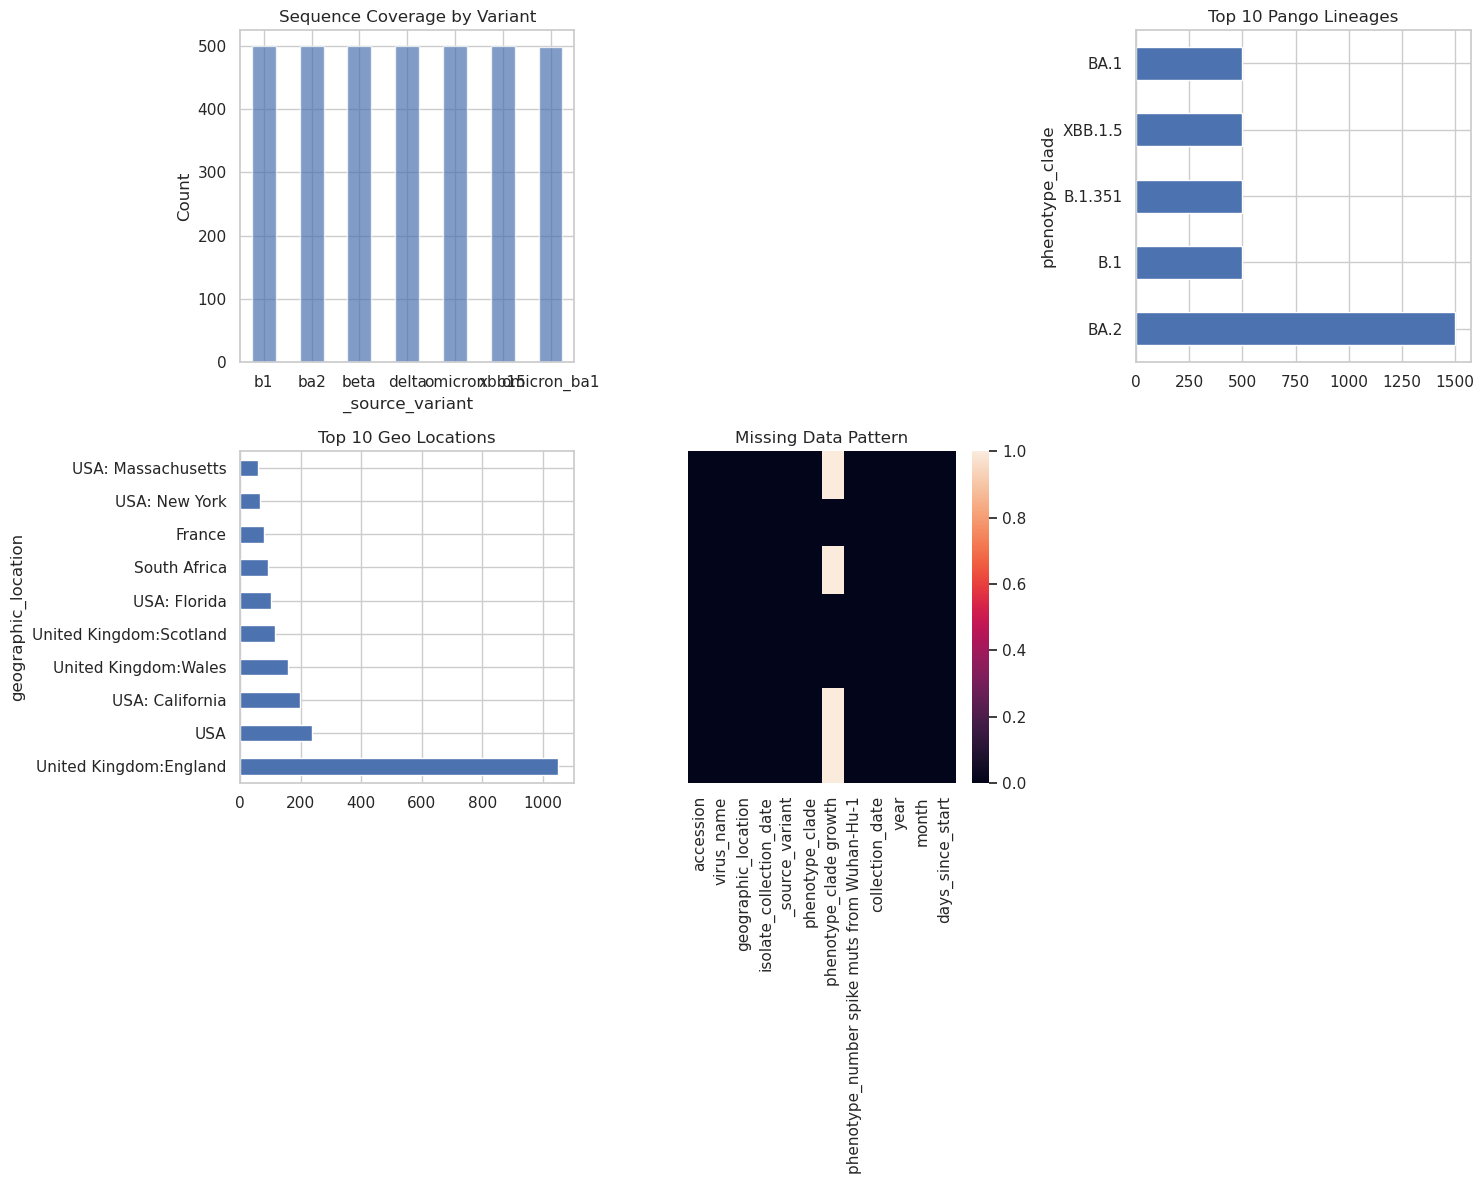

In [33]:

plt.figure(figsize=(15, 12))

# Distribution of Variant
plt.subplot(2, 3, 1)
merged_df['_source_variant'].value_counts().plot(kind='bar', alpha=0.7)
plt.title("Sequence Coverage by Variant")
plt.ylabel("Count")
plt.xticks(rotation=0)

# Top phenotype_clade
plt.subplot(2, 3, 3)
top_pango = merged_df['phenotype_clade'].value_counts().head(10)
top_pango.plot(kind='barh')
plt.title("Top 10 Pango Lineages")

# Geo_Location 
plt.subplot(2, 3, 4)
top_geo = merged_df['geographic_location'].value_counts().head(10)
top_geo.plot(kind='barh')
plt.title("Top 10 Geo Locations")

# Missing data heatmap
plt.subplot(2, 3, 5)
sns.heatmap(merged_df.isnull(), cbar=True, yticklabels=False)
plt.title("Missing Data Pattern")

plt.tight_layout()
plt.show()


EXPLORATORY DATA ANALYSIS 

TARGET VARIABLE: phenotype_clade growth
  Shape: (3499,)
  Non-null: 1500 (42.9%)

  Statistics:
  - Mean: 0.7440
  - Std: 0.0000
  - Min: 0.7440
  - Median: 0.7440
  - Max: 0.7440


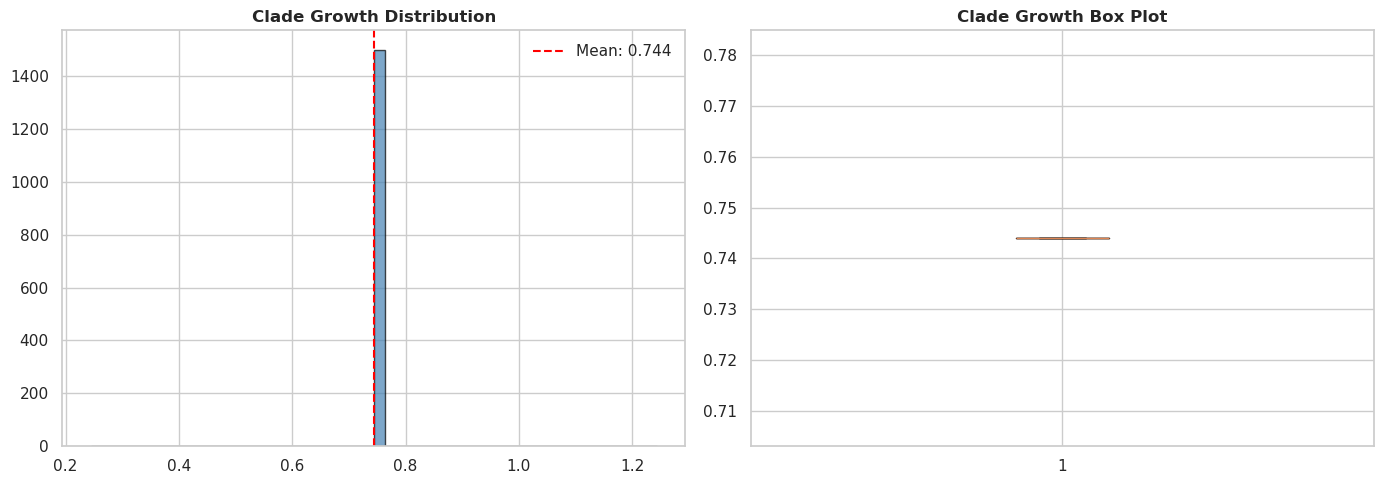

In [35]:
# Create results directory
os.makedirs('results/figures', exist_ok=True)

print("EXPLORATORY DATA ANALYSIS ")

# Target Variable Analysis
target_col = 'phenotype_clade growth'
print(f"\nTARGET VARIABLE: {target_col}")
print(f"  Shape: {merged_df[target_col].shape}")
print(f"  Non-null: {merged_df[target_col].notna().sum()} ({merged_df[target_col].notna().sum()/len(merged_df)*100:.1f}%)")

# Basic Statistics
target_clean = merged_df[target_col].dropna()
print(f"\n  Statistics:")
print(f"  - Mean: {target_clean.mean():.4f}")
print(f"  - Std: {target_clean.std():.4f}")
print(f"  - Min: {target_clean.min():.4f}")
print(f"  - Median: {target_clean.median():.4f}")
print(f"  - Max: {target_clean.max():.4f}")

# Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(target_clean, bins=50, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].axvline(target_clean.mean(), color='red', linestyle='--', label=f'Mean: {target_clean.mean():.3f}')
axes[0].set_title('Clade Growth Distribution', fontweight='bold')
axes[0].legend()

axes[1].boxplot(target_clean, vert=True)
axes[1].set_title('Clade Growth Box Plot', fontweight='bold')

plt.tight_layout()
plt.savefig('results/figures/01_target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


The initial EDA of the target variable, clade_growth, reveals a concentrated distribution around the mean value of 0.744. The box plot appears as a single horizontal line, indicating near zero variance in the current merged dataset. This is a direct consequence of the data granularity: while genomic data is specific to the sequence, the phenotypic labels from the Bloom Lab are assigned at the clade level. If the dataset is dominated by a single predominant lineage, the model effectively sees a constant value for the target. 

### Variant coverage

This analysis evaluates how different SARS-CoV-2 variants are represented across the sequences, which is fundamental for ensuring the model's generalizability.


 VARIANT COVERAGE (_source_variant):
    Variant  Count  Percentage
         b1    500   14.289797
        ba2    500   14.289797
       beta    500   14.289797
      delta    500   14.289797
    omicron    500   14.289797
      xbb15    500   14.289797
omicron_ba1    499   14.261217


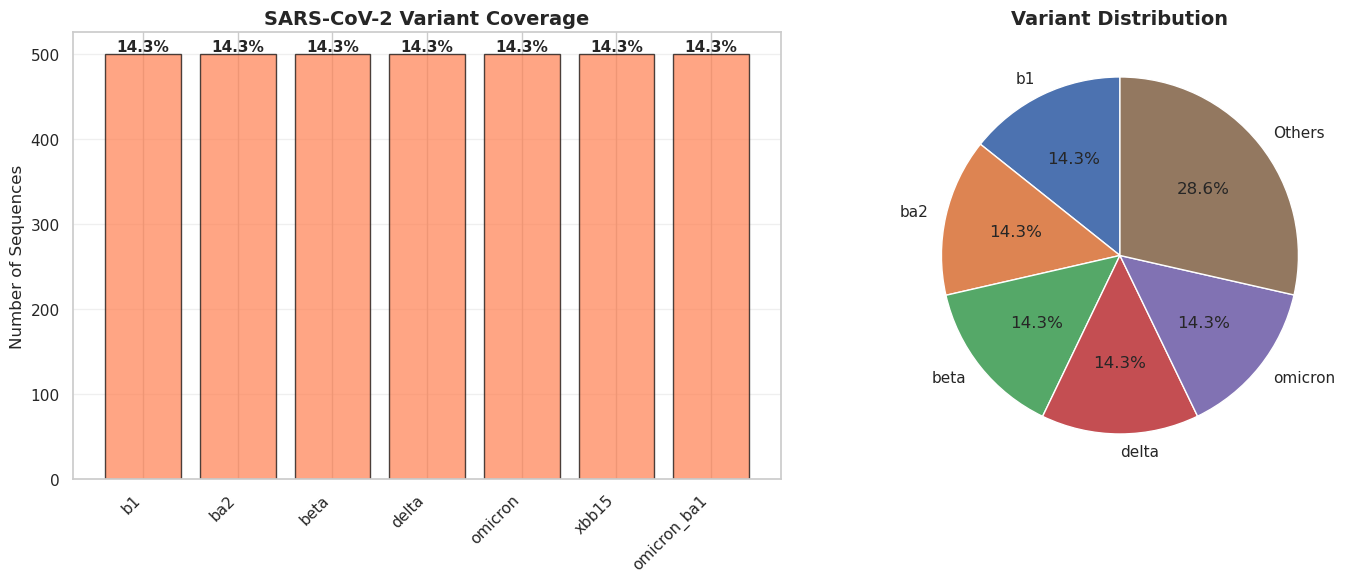

In [40]:
variant_col = '_source_variant' 

print(f"\n VARIANT COVERAGE ({variant_col}):")
variant_counts = merged_df[variant_col].value_counts()
variant_pct = (variant_counts / len(merged_df)) * 100

variant_df = pd.DataFrame({
    'Variant': variant_counts.index,
    'Count': variant_counts.values,
    'Percentage': variant_pct.values
})
print(variant_df.to_string(index=False))

# Variant Coverage
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Bar plot
bars = ax1.bar(range(len(variant_df)), variant_df['Count'], color='coral', edgecolor='black', alpha=0.7)
ax1.set_xticks(range(len(variant_df)))
ax1.set_xticklabels(variant_df['Variant'], rotation=45, ha='right')
ax1.set_ylabel('Number of Sequences', fontsize=12)
ax1.set_title('SARS-CoV-2 Variant Coverage', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')

# Add count labels
for i, (bar, pct) in enumerate(zip(bars, variant_df['Percentage'])):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height, f'{pct:.1f}%', 
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Pie chart (t
top5 = variant_df.head(5)
others = pd.DataFrame({'Variant': ['Others'], 'Count': [variant_df['Count'][5:].sum()], 
                      'Percentage': [variant_df['Percentage'][5:].sum()]})
pie_df = pd.concat([top5, others], ignore_index=True)

ax2.pie(pie_df['Count'], labels=pie_df['Variant'], autopct='%1.1f%%', startangle=90)
ax2.set_title('Variant Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


## Spatial Distribution

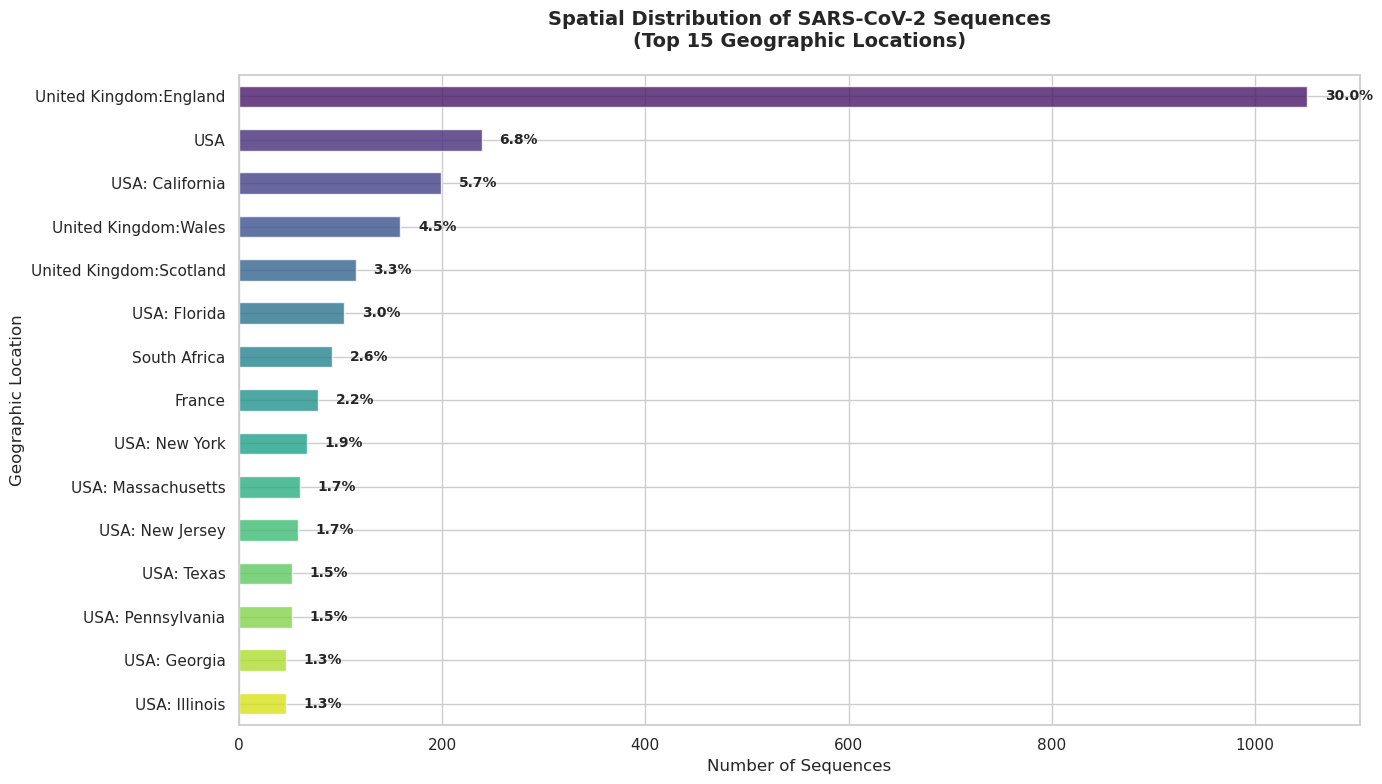

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

location_col = 'geographic_location'
valid_locations = merged_df[location_col].notna().sum()
total_records = len(merged_df)

# Prepare data for Top 15 Locations
location_counts = merged_df[location_col].value_counts().head(15)


plt.figure(figsize=(14, 8))
sns.set_style("whitegrid")

# Create a horizontal bar chart for better readability of location names
colors = sns.color_palette("viridis", len(location_counts))
location_counts.plot(kind='barh', color=colors, alpha=0.8)

plt.title('Spatial Distribution of SARS-CoV-2 Sequences\n(Top 15 Geographic Locations)', 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Number of Sequences', fontsize=12)
plt.ylabel('Geographic Location', fontsize=12)
plt.gca().invert_yaxis()  

# Add percentage labels to the bars for context
for i, v in enumerate(location_counts.values):
    plt.text(v + (total_records * 0.005), i, f'{(v/total_records)*100:.1f}%', 
             va='center', fontsize=10, fontweight='bold')

plt.tight_layout()

### Data Gaps Analysis (Heatmap)

In here, we performed the exploration by focusing on the density and availability of phenotypic traits within the integrated dataset to identify viable targets for predictive modeling. This diagnostic step is essential for distinguishing between informative experimental metrics and those compromised by excessive missingness or lack of variance.

COLUNAS DISPONÍVEIS: ['phenotype_clade growth', 'phenotype_number spike muts from Wuhan-Hu-1', 'days_since_start', 'year', 'month']


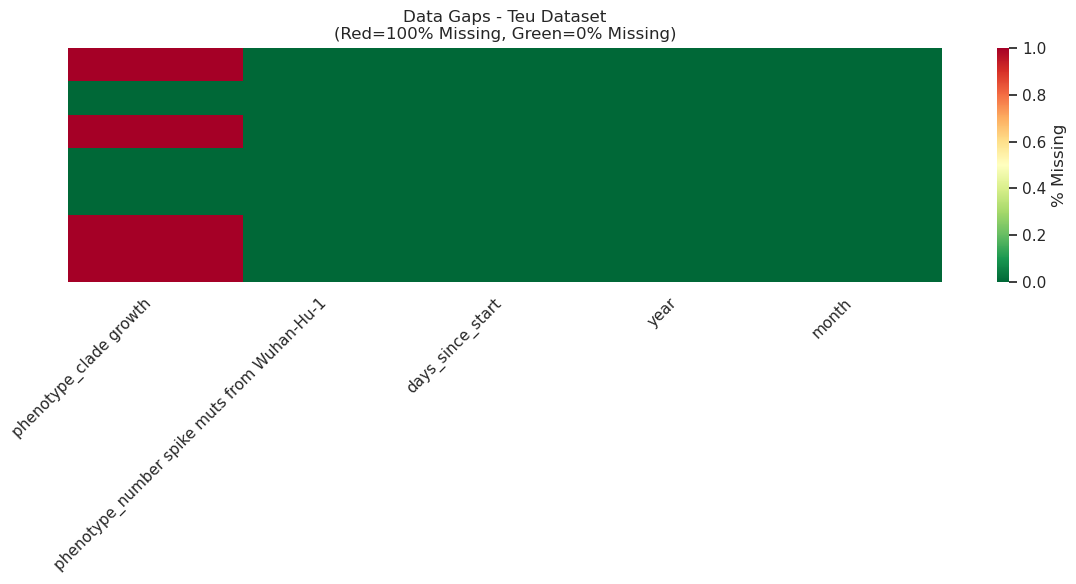


% MISSING por coluna:
phenotype_clade growth                         57.130609
phenotype_number spike muts from Wuhan-Hu-1     0.000000
days_since_start                                0.000000
year                                            0.000000
month                                           0.000000
dtype: float64


In [49]:
available_cols = ['phenotype_clade growth', 'phenotype_number spike muts from Wuhan-Hu-1', 
                  'days_since_start', 'year', 'month']

real_cols = [col for col in available_cols if col in merged_df.columns]
print(f"COLUNAS DISPONÍVEIS: {real_cols}")

if real_cols:
    phenotype_df = merged_df[real_cols].copy()
    
    plt.figure(figsize=(12, 6))
    sns.heatmap(phenotype_df.isnull(), 
                cbar=True, cmap='RdYlGn_r', yticklabels=False,
                cbar_kws={'label': '% Missing'})
    plt.title('Data Gaps - Teu Dataset\n(Red=100% Missing, Green=0% Missing)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    print("\n% MISSING por coluna:")
    print(phenotype_df.isnull().mean() * 100)
else:
    print("NENHUMA coluna phenotype encontrada!")


## Genomic Vectorization

Each unique mutation in the Spike protein is converted into an individual feature, where a value of 1 indicates the presence of a mutation and 0 indicates its absence. By expanding the 'Variant' strings into a mutation matrix, we capture the specific genetic configuration of each sequence while preserving the biological signal required to predict phenotypic outcomes.

This transformation is essential for machine learning algorithms because they require numerical input.

In [48]:
# Transform the categorical mutation 'alphabet' into a binary numerical matrix
if 'Variant' in merged_df.columns:
    # Use get_dummies with a comma separator to isolate individual amino acid mutations
    mutation_dummies = merged_df['Variant'].str.get_dummies(sep=',')
    
    # Concatenate the new binary features with the original integrated dataframe
    merged_df = pd.concat([merged_df, mutation_dummies], axis=1)

# Verification of the numerical transformation 
merged_df.shape

(3499, 12)

## Next Step: Transition to the Machine Learning Phase (Model Development)

The preparation and EDA notebooks confirm that the dataset meets the essential requirements for ML training:

* The dataset is **clean and ML-ready**, with no duplicate accessions and full consistency checks completed.
* Variant representation is **balanced** through stratified downsampling (**500 sequences per variant**, total **3,500 samples**).
* The chosen target variable, **`phenotype_number_spike_muts`**, has **0% missing values**, ensuring no loss of samples during training.
* Feature engineering is already in place, including:

  * temporal features (year, month, days since pandemic start),
  * metadata features (location and variant),
  * and **binary one-hot encoding** for spike mutation presence.

Additionally, EDA indicates a strong underlying signal in the data: spike mutation density shows a **high correlation with the fitness proxy**, and PCA suggests that much of the variability in the dataset can be captured in a lower-dimensional representation. Together, these findings justify moving forward with supervised learning models.


## Key Note on Limitations

A critical limitation acknowledged during EDA is that the original phenotype growth metric (`phenotype_clade_growth`) is missing for a large portion of the dataset. Therefore, the project uses spike mutation count as a **fitness proxy**, not a direct measurement of transmissibility or biological fitness. This means model predictions should be interpreted as **genomic complexity/escape potential indicators**, rather than absolute real-world fitness.




